# Native FastReso `*_Fj.out` vs `runcascade`, on a realistic list

Runs upstream FastReso's **own** driver, reads the `*_Fj.out` files it writes,
and compares them against this repository's `runcascade`. No custom exporter is
involved at any point — only `run_fastreso_azyhydro.exe` and its native output.

Set `MASS_CUT` to trim the full decay list down to a thermally relevant subset,
or to `nothing` to use a fixture unchanged.

## The step that makes this work

`*_Fj.out` is **not** a spectrum, and it is not the same observable as
`runcascade`. It stores irreducible components in one static fluid cell at
`ur = 0`, a function of `|p|`. `runcascade` produces the boost-invariant mode-0
projection, which integrates over rapidity.

Compared directly they disagree by `2.95, 2.04, 1.33, 1.12` at
`p = 0.05, 0.2, 0.5, 1.0 GeV` — drifting with momentum, so not a normalization.
Take `Feq 2`, convert to the static spectrum, then **integrate over rapidity**:

$$F_{\rm proj}(p_T) = 4\pi \int_0^{\eta_{\max}} d\eta\; F_{\rm static}\big(p(\eta)\big),
\qquad E = m_T\cosh\eta,\; p=\sqrt{E^2-m^2}$$

Section 7 checks that against closed-form Bose-Einstein before anything is
compared.

## 1. Setup

In [31]:
using Printf, Statistics

# Notebook-only dependencies. They are installed into the shared default
# environment rather than the repository's Project.toml, which stays a
# description of what the *library* needs. The default environment is on
# LOAD_PATH, so these import fine while --project=Fast_reso2 is active.
using Pkg
let project = Base.active_project()
    for name in ("QuadGK", "Interpolations", "PyPlot")
        Base.find_package(name) === nothing || continue
        @info "installing $name into the default environment (not Project.toml)"
        Pkg.activate(); Pkg.add(name); Pkg.activate(project)
    end
end
using QuadGK: quadgk
using Interpolations: interpolate, extrapolate, Gridded, Linear, Flat
using PyPlot

REPO = let dir = pwd()
    while !isfile(joinpath(dir, "CascadeTables.jl")) && dir != dirname(dir)
        dir = dirname(dir)
    end
    dir
end
BENCH = joinpath(REPO, "benchmarks", "fastreso_crosscheck")
OUT = joinpath(BENCH, "output");  mkpath(OUT)

# Guarded: re-running this cell would otherwise `include` the module a second
# time, and names exported by both the stale and fresh copy become ambiguous
# ("UndefVarError: `nbody` not defined in `Main`"). To pick up edits to the
# .jl files, restart the kernel.
isdefined(Main, :CascadeTables) || include(joinpath(REPO, "CascadeTables.jl"))
using .CascadeTables

function plot_params(; gui = false, pHeight = 2.3)
    close("all")
    pygui(gui)
    rc("text", usetex = "true")
    rc("font", family = "serif")
    rc("font", size = 12)
    rc("xtick", labelsize = 12)
    rc("ytick", labelsize = 12)
    rc("lines", markersize = 1)
    rc("legend", fontsize = 10)
    rc("axes", titlesize = 12)
    rc("axes", titlepad = 10)
    return nothing
end
pHeight = 2.3
pWidth = 1.3333333 * pHeight
plot_params()

FASTRESO_DIR = get(ENV, "FASTRESO_DIR", joinpath(homedir(), "FastReso"))
DRIVER = joinpath(FASTRESO_DIR, "build", "run_fastreso_azyhydro.exe")

@printf("repo    %s\n", REPO)
@printf("driver  %s\n", isfile(DRIVER) ? DRIVER : "MISSING -- build FastReso, see README")

repo    /Users/eduardogrossi/Fast_reso2
driver  /Users/eduardogrossi/FastReso/build/run_fastreso_azyhydro.exe


## 2. Configuration

Two things are **hard-coded upstream** in `run_fastreso_azyhydro.cpp` and cannot
be passed in:

- the freeze-out temperature, `T = 0.145 GeV`;
- which particles get written — `pdg[] = {211, 321, 2212, 3122, 3312, 3334}`,
  i.e. pi+, K+, p, Lambda, Xi-, Omega-.

`MASS_CUT` controls the size of the problem:

| cut [GeV] | species | channels | driver time |
|---|---|---|---|
| 1.2 | 37 | 64 | ~20 s |
| **1.4** | **79** | **190** | **~80 s** |
| 1.6 | 167 | 695 | minutes |
| `nothing` | fixture as-is | | seconds |

The native driver is slower than the repository's exporter on the same list
(~80 s against ~13 s at 1.4 GeV) because it computes all 13 irreducible
components rather than just `Feq 2`.

In [32]:
SOURCE_LIST = joinpath(REPO, "decays_QM2016Plus_massorder.dat")
MASS_CUT = 1.4                     # GeV; set to `nothing` to use SOURCE_LIST unchanged

TEMPERATURE = 0.145                # fixed inside run_fastreso_azyhydro.cpp
FJ_DIR = joinpath(OUT, "fjout")

ORDERS = (nq = 64, nθ = 16, nµ = 16, nσ = 16, nma = 16)
GRID = range(0.0001, 8.0, length = 401)   # uniform range; must extend well past
                                          # PMAX so parents feeding high-pT
                                          # daughters are not truncated
ETAMAX = 5.0                       # TKernel's fixed |eta| window
QUAD_RTOL = 1e-10                  # adaptive rapidity quadrature tolerance
PMIN, PMAX = 0.1, 3.0              # comparison window

@printf("source %s\n", basename(SOURCE_LIST))
@printf("cut    %s\n", MASS_CUT === nothing ? "none" : "$(MASS_CUT) GeV")

source decays_QM2016Plus_massorder.dat
cut    1.4 GeV


## 3. Trim the list

Keep every species at or below the cut, and every channel whose daughters all
survive. Row order is preserved, which matters because upstream requires
**feeder-before-fed** ordering and the file is already mass-descending.

**A mass cut is self-closing.** A daughter is always lighter than its parent, so
if the parent survives the cut its daughters do too — `dropped` comes out zero
and no branching ratio needs repairing. What is lost is feed-down *from* heavier
resonances: a stated truncation of the physics, not a broken file.

In [33]:
function trim_decay_list(source, destination; mass_cut)
    lines = readlines(source)
    kept = Set(parse(Int, f[1]) for f in split.(lines) if length(f) == 12 &&
               parse(Float64, f[3]) <= mass_cut)

    blocks = Vector{Tuple{Vector{SubString{String}},Vector{Vector{SubString{String}}}}}()
    for line in lines
        fields = split(line)
        if length(fields) == 12
            push!(blocks, (fields, Vector{Vector{SubString{String}}}()))
        elseif length(fields) == 8 && !isempty(blocks)
            push!(blocks[end][2], fields)
        end
    end

    written = dropped = terminal = 0
    open(destination, "w") do io
        for (header, channels) in blocks
            parse(Int, header[1]) in kept || continue
            physical = filter(c -> parse(Int, c[2]) > 1, channels)   # skip self-channels
            usable = filter(physical) do channel
                count = parse(Int, channel[2])
                all(parse(Int, channel[3 + i]) in kept for i in 1:count)
            end
            dropped += length(physical) - length(usable)
            if isempty(usable)
                terminal += 1
                println(io, join(vcat(header[1:11], "1"), "\t"))
                println(io, join([header[1], "1", "1", header[1], "0", "0", "0", "0"], "\t"))
            else
                written += length(usable)
                println(io, join(vcat(header[1:11], string(length(usable))), "\t"))
                foreach(c -> println(io, join(c, "\t")), usable)
            end
        end
    end
    (species = length(kept), channels = written, dropped, terminal)
end

DECAY_LIST = if MASS_CUT === nothing
    SOURCE_LIST
else
    path = joinpath(OUT, "trimmed_$(MASS_CUT).dat")
    report = trim_decay_list(SOURCE_LIST, path; mass_cut = MASS_CUT)
    @printf("%d species, %d channels, %d terminal, %d dropped for closure\n",
            report.species, report.channels, report.terminal, report.dropped)
    path
end
validate(DecayList(DECAY_LIST))

79 species, 190 channels, 22 terminal, 0 dropped for closure
── decay-list validation ────────────────────────────────────────────
  79 particles, 190 decay channels (22 stable), multiplicities [1 => 22, 2 => 146, 3 => 36, 4 => 8]
  conservation (must be zero):
    charge violations ........ OK
    baryon-number violations . OK
    unresolved daughters ..... OK
    BR out of [0,1] .......... OK
  branching ratios: max |ΣBR-1| = 1.00e-09,  OK parents beyond 2%
  informational: 0 strangeness-changing, 0 charm-changing (weak decays),  0 closed-at-pole
──────────────────────────────────────────────────────────────────────


(particles = 79, channels = 190, selfstable = 22, multiplicity = [1 => 22, 2 => 146, 3 => 36, 4 => 8], unresolved = 0, br_out_of_range = 0, charge_violations = 0, baryon_violations = 0, strangeness_changing = 0, charm_changing = 0, subthreshold = 0, br_norm_outliers = 0, br_maxdev = 9.99999860695766e-10)

## 4. Run upstream's own driver

Writes `_thermal_` (primary only) and `_total_` (after the full cascade) per
particle. This is the slow cell.

In [34]:
rm(FJ_DIR; recursive = true, force = true);  mkpath(FJ_DIR)
driver_seconds = @elapsed run(pipeline(`$DRIVER $DECAY_LIST $(FJ_DIR)/`,
                                       stdout = devnull, stderr = devnull))
written = filter(name -> endswith(name, "_Fj.out"), readdir(FJ_DIR))
@printf("%.1f s, %d files\n", driver_seconds, length(written))

79.8 s, 12 files


## 5. Read `*_Fj.out`

The file stores irreducible components on FastReso's native `pbar` grid:

```
# mc-number  name  mass  width  deg  Qb Qs Qc Qbot isospin charge decays  Nyield
# 1:pbar  2:m  3:Feq 1  4:Feq 2  5:Fshear 1  ...  14:Fvel 3
```

At `ur = 0` only `Feq 2` (column 4) contributes, and

$$E\,\frac{dN}{d^3p} = \frac{\nu}{(2\pi)^3}\,\frac{E}{\bar p}\,F_{eq,2}(\bar p),
\qquad E=\sqrt{m^2+\bar p^2}$$

**The filename is not authoritative.** `run_fastreso_azyhydro.cpp` requests a
fixed PDG array, and if a species is not in the decay list it writes the file
anyway with whatever `getParticleByPDG` returned. Trimming at 1.4 GeV excludes
Omega- (1.672 GeV), and the resulting `PDGid_3334_*` file contains
**Sigma(1385)-** instead. So the mc-number in the header is checked against the
filename and mismatches are skipped.

The grid is `pbar = tan(...)`: 401 points, `0.0036` to `8.5 GeV`, spacing
varying by a factor of 71. That non-uniformity is why `CascadeTable` — which
takes an `AbstractRange` — cannot consume it directly.

In [36]:
struct FjSpectrum
    pdg::Int
    mass::Float64
    degeneracy::Float64
    yield::Float64
    momenta::Vector{Float64}
    spectrum::Vector{Float64}      # E dN/d^3p
end

function read_fj(path)
    header, rows = String[], Vector{Float64}[]
    for line in eachline(path)
        startswith(line, "#") ? push!(header, line) : push!(rows, parse.(Float64, split(line)))
    end
    length(header) >= 2 || error("$path: expected the two-line Fj header")
    fields = split(header[2])
    mass = parse(Float64, fields[4]);  degeneracy = parse(Float64, fields[6])
    momenta = [row[1] for row in rows]
    energies = hypot.(mass, momenta)
    FjSpectrum(parse(Int, fields[2]), mass, degeneracy, parse(Float64, fields[end]),
               momenta, degeneracy .* energies ./ ((2π)^3 .* momenta) .* [row[4] for row in rows])
end

decay_list = filter(nbody(2, 3), DecayList(DECAY_LIST))   # upstream implements 2-/3-body only

fj = Dict{Int,NamedTuple}()
for name in readdir(FJ_DIR)
    occursin("_total_", name) || continue
    requested = parse(Int, split(name, "_")[2])
    total = read_fj(joinpath(FJ_DIR, name))
    if total.pdg != requested                     # see the note above
        @warn "skipping $name: header says PDG $(total.pdg), filename says $requested"
        continue
    end
    haskey(decay_list.parts, requested) || continue
    primary = read_fj(joinpath(FJ_DIR, replace(name, "_total_" => "_thermal_")))
    fj[requested] = (; primary, total)
end
@printf("usable: %s\n", join(sort!(collect(keys(fj))), ", "))

┌ Warning: skipping PDGid_3334_total_T0.1450_Fj.out: header says PDG 3114, filename says 3334
└ @ Main /Users/eduardogrossi/Fast_reso2/benchmarks/fastreso_crosscheck/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_Y200sZmlsZQ==.jl:32


usable: 211, 321, 2212, 3122, 3312


## 6. Project, and run the local cascade

`project` turns the static Fj spectrum into the boost-invariant one. The static
values live on the tangent grid, so the integrand is interpolated in `log F`
against `p` — the spectrum is near-exponential, which makes that far more
accurate than interpolating `F`. `quadgk` is adaptive and reports its own error,
so the quadrature is not a tuning parameter.

Because `project` evaluates at any `pT`, it is called **at the cascade's own
grid points** — the Julia side is never interpolated.

In [37]:
function log_interpolant(sample)
    values = log.(max.(sample.spectrum, 1e-300))
    interpolant = extrapolate(interpolate((sample.momenta,), values, Gridded(Linear())), Flat())
    momentum -> momentum >= last(sample.momenta) ? 0.0 : exp(interpolant(momentum))
end

function project(transverse_momentum, mass, interpolant)
    transverse_mass = hypot(mass, transverse_momentum)
    value, estimate = quadgk(0.0, ETAMAX; rtol = QUAD_RTOL) do rapidity
        energy = transverse_mass * cosh(rapidity)
        interpolant(sqrt(max(energy^2 - mass^2, 0.0)))
    end
    # 4pi = 2pi (source azimuth) x 2 (folding the symmetric |eta| window onto
    # [0, eta_max]). Integrating the full range as well would double-count.
    4π * value, 4π * estimate
end

momenta = collect(GRID)
projected = Dict(id => begin
        interpolants = (log_interpolant(pair.primary), log_interpolant(pair.total))
        results = ([project(p, pair.total.mass, interpolants[1]) for p in momenta],
                   [project(p, pair.total.mass, interpolants[2]) for p in momenta])
        (primary = first.(results[1]), total = first.(results[2]),
         quadrature = maximum(last.(results[1]) ./ first.(results[1])))
    end for (id, pair) in fj)

function thermal_primary(particle, momenta)
    particle.mass > 0.001 || return zeros(length(momenta))   # upstream leaves photons uninitialized
    degeneracy = round(Int, particle.degeneracy)
    is_fermion = iseven(degeneracy)
    map(momenta) do momentum
        transverse_mass = hypot(particle.mass, momentum)
        integral, _ = quadgk(0.0, ETAMAX; rtol = QUAD_RTOL) do rapidity
            energy = transverse_mass * cosh(rapidity)
            exponent = energy / TEMPERATURE
            distribution = exponent > 700 ? 0.0 :
                is_fermion ? inv(exp(exponent) + 1) : inv(expm1(exponent))
            energy * distribution
        end
        4π * degeneracy * integral / (2π)^3
    end
end

primary_by_id = Dict(id => thermal_primary(decay_list.parts[id], momenta)
                     for id in keys(decay_list.parts))
primary(particle, mode, requested) =
    mode == 0 ? copy(primary_by_id[particle.id]) : zeros(length(requested))

table_seconds = @elapsed table = CascadeTable(decay_list; grid = GRID, modes = [0],
                                              orders = ORDERS, width_cut = Inf)
plan_seconds = @elapsed plan = CascadePlan(table, decay_list)
run_seconds = @elapsed result = runcascade(plan; primary, output = :all)
@printf("particles=%d channels=%d keys=%d\ntable=%.2f s plan=%.2f s run=%.1f ms\n",
        length(decay_list.parts), sum(length, values(decay_list.byparent)),
        length(table.W), table_seconds, plan_seconds, 1e3 * run_seconds)

particles=79 channels=182 keys=191
table=0.90 s plan=0.00 s run=441.2 ms


## 7. Are the conversion and the projection right?

Two checks independent of the decay physics: the static primary from `Feq 2`
against closed-form Bose-Einstein, and the **projected** primary against this
repository's own thermal projector. A failure in either contaminates everything
downstream.

In [38]:
window = PMIN .<= momenta .<= PMAX
@printf("%7s %14s %14s %12s\n", "pdg", "static vs BE", "proj vs proj", "quadrature")
for id in sort!(collect(keys(fj)))
    sample = fj[id].primary
    # Fermi-Dirac for half-integer spin, Bose-Einstein otherwise. Using expm1
    # for everything reads as a 1e-3 "disagreement" on p, Lambda and Xi while
    # pions and kaons look fine -- the signature of wrong statistics, not a bug
    # in either code.
    is_fermion = iseven(round(Int, sample.degeneracy))
    closed = [sample.degeneracy * hypot(sample.mass, p) / (2π)^3 *
              (is_fermion ? inv(exp(hypot(sample.mass, p) / TEMPERATURE) + 1) :
                            inv(expm1(hypot(sample.mass, p) / TEMPERATURE)))
              for p in sample.momenta]
    inside = sample.momenta .<= PMAX
    static_error = maximum(abs.(closed .- sample.spectrum)[inside] ./ sample.spectrum[inside])
    projection_error = maximum((abs.(projected[id].primary .- primary_by_id[id]) ./
                                primary_by_id[id])[window])
    @printf("%7d %14.3e %14.3e %12.3e\n", id, static_error, projection_error,
            projected[id].quadrature)
end
@printf("\n(Fj.out prints %%15.5e -- 6 significant digits -- so ~1e-6 is the floor)\n")

    pdg   static vs BE   proj vs proj   quadrature
    211      3.240e-05      2.163e-05    1.000e-10
    321      3.302e-05      2.597e-05    1.000e-10
   2212      2.956e-05      3.839e-05    9.999e-11
   3122      3.052e-05      4.347e-05    9.999e-11
   3312      2.687e-05      4.979e-05    1.000e-10

(Fj.out prints %15.5e -- 6 significant digits -- so ~1e-6 is the floor)


## 8. Plots

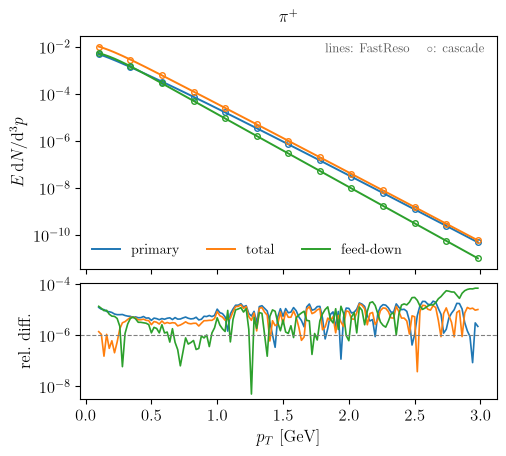

In [41]:
# usetex is on, so labels are LaTeX. Unknown species fall back to escaped text.
const LATEX_NAME = Dict(
    211 => raw"$\pi^+$",   -211 => raw"$\pi^-$",    111 => raw"$\pi^0$",
    321 => raw"$K^+$",      -321 => raw"$K^-$",
   2212 => raw"$p$",       -2212 => raw"$\bar{p}$",
   3122 => raw"$\Lambda$", 3312 => raw"$\Xi^-$",   3334 => raw"$\Omega^-$",
   3212 => raw"$\Sigma^0$")

latex_name(id) = get(LATEX_NAME, id,
                     "\\mathrm{" * replace(decay_list.parts[id].name, "_" => "\\_") * "}" |>
                     text -> "\$" * text * "\$")

function plot_particle(particle_id)
    reference = projected[particle_id]
    local_primary = primary_by_id[particle_id]
    local_total = result.F[particle_id][1]
    curves = ((raw"primary", reference.primary, local_primary),
              (raw"total", reference.total, local_total),
              (raw"feed-down", reference.total .- reference.primary,
                               local_total .- local_primary))
    inside = findall(window)
    marks = inside[1:12:end]

    figure_handle, axes = subplots(2, 1, sharex = true,
        figsize = (pWidth * 1.7, pHeight * 2.0),
        gridspec_kw = Dict("height_ratios" => [2, 1], "hspace" => 0.08))
    upper, lower = axes[1], axes[2]

    for (index, (label, reference_values, candidate_values)) in enumerate(curves)
        colour = "C$(index - 1)"
        # Only the reference line carries a label: six legend entries overflow
        # the axes, and the annotation below says which is which.
        upper.plot(momenta[inside], reference_values[inside], "-", color = colour,
                   lw = 1.4, label = label)
        upper.plot(momenta[marks], candidate_values[marks], "o", color = colour,
                   ms = 4, mfc = "none", mew = 1.0)
        residual = abs.(candidate_values .- reference_values) ./ abs.(reference_values)
        lower.plot(momenta[inside], residual[inside], "-", color = colour, lw = 1.2)
    end

    upper.set_yscale("log")
    upper.set_ylabel(raw"$E\,\mathrm{d}N/\mathrm{d}^3p$")
    upper.set_title(latex_name(particle_id))
    upper.legend(frameon = false, ncol = 3, loc = "lower left")
    upper.text(0.97, 0.93, raw"lines: FastReso \quad $\circ$: cascade", ha = "right",
               transform = upper.transAxes, fontsize = 9, color = "0.35")
    #upper.grid(alpha = 0.25)

    lower.set_yscale("log")
    lower.set_xlabel(raw"$p_T$ [GeV]")
    lower.set_ylabel(raw"rel.\ diff.")
    lower.axhline(1e-6, color = "0.5", ls = "--", lw = 0.8)   # Fj print-precision floor
    #lower.grid(alpha = 0.25, which = "both")

    # tight_layout fights the gridspec hspace; set the margins explicitly.
    figure_handle.subplots_adjust(left = 0.17, right = 0.97, top = 0.92, bottom = 0.13)
    figure_handle
end

plot_particle(first(sort!(collect(keys(fj)))))

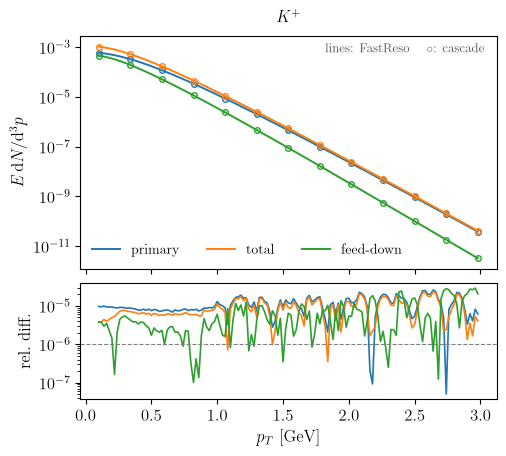

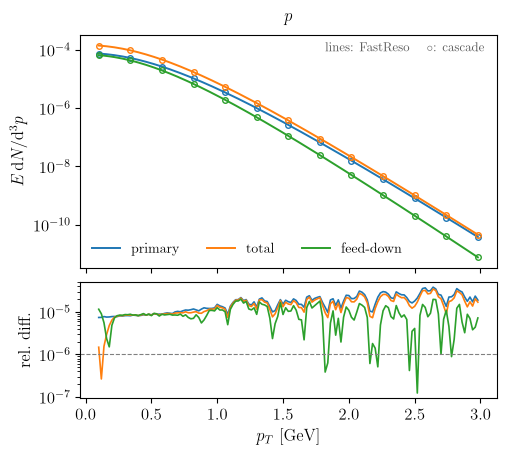

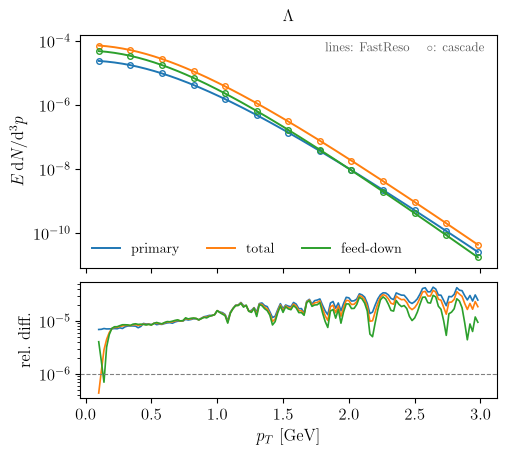

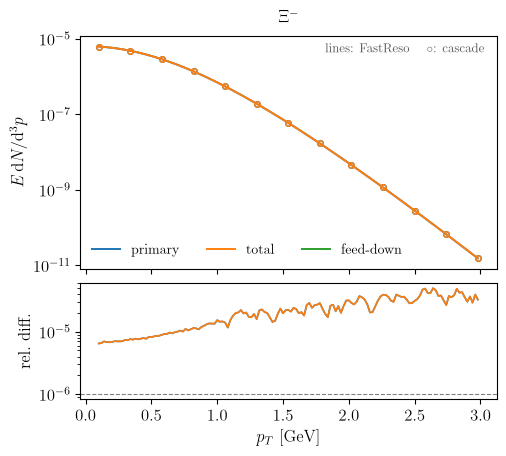

In [42]:
for id in sort!(collect(keys(fj)))[2:end]
    display(plot_particle(id))
end

## 9. Numbers

In [ ]:
summary_rows = [
    let reference = projected[particle_id],
        local_primary = primary_by_id[particle_id],
        local_total = result.F[particle_id][1],
        pair = quantity === :primary ? (reference.primary, local_primary) :
               quantity === :total   ? (reference.total, local_total) :
                                       (reference.total .- reference.primary,
                                        local_total .- local_primary),
        scale = maximum(abs, pair[1][window]),
        # A species with no open channel below the mass cut has identically zero
        # feed-down on both sides. That is exact agreement, not 0/0.
        errors = scale == 0 ? Float64[] : (abs.(pair[2] .- pair[1]) ./ abs.(pair[1]))[window]
        (particle_id, decay_list.parts[particle_id].name, quantity, length(errors),
         isempty(errors) ? 0.0 : maximum(errors),
         isempty(errors) ? 0.0 : sqrt(mean(abs2, errors)),
         isempty(errors) ? 0.0 : momenta[window][argmax(errors)])
    end
    for particle_id in sort!(collect(keys(fj)))
    for quantity in (:primary, :total, :feed)
]

@printf("%7s %-14s %10s %5s %12s %12s %9s\n",
        "pdg", "name", "quantity", "n", "max rel", "RMS rel", "worst p")
for (particle_id, name, quantity, n, maximum_error, rms_error, worst) in summary_rows
    n == 0 ?
        @printf("%7d %-14s %10s %5s %12s\n", particle_id, name, quantity, "-",
                "identically zero (terminal in this list)") :
        @printf("%7d %-14s %10s %5d %12.3e %12.3e %9.3f\n",
                particle_id, name, quantity, n, maximum_error, rms_error, worst)
end
@printf("\nworst overall %.3e\n", maximum(row[5] for row in summary_rows))

## 10. Reading the result

**The floor is `~1e-5`, set by the file format.** `*_Fj.out` is written with
`%15.5e` — six significant digits. The repository's own exporter writes 17
digits precisely so the comparison is not limited this way; `RESULTS.md` quotes
`9.95e-8` for the two-body channel, far below anything visible here.

Three error sources stack that `run_small.sh` avoids: the six-digit print
precision, the log-interpolation of the tangent grid, and the rapidity
quadrature. `quadgk` reports the last one (`~1e-10`), so the residual is the
first two.

### Things that will bite

- **The filename is not authoritative.** See section 5 — a species missing from
  the decay list still gets a file, containing a different particle.
- **`T` and the particle list are hard-coded** in `run_fastreso_azyhydro.cpp`.
- **The `4pi` prefactor already contains a factor 2** — `2pi` azimuth times `2`
  for folding `[-eta_max, eta_max]` onto `[0, eta_max]`. Integrating the
  symmetric range on top of it gives a clean factor of 2.00 at every momentum.
- **`GRID` must extend well past `PMAX`.** Stopping at 3.5 GeV while comparing
  to 3.0 truncates the parents feeding high-pT daughters and inflates the
  feed-down error to `7e-2`.
- **`ETAMAX = 5.0`** must match the window upstream integrates over. It is not
  recorded in `Fj.out`, so it is assumed here.
- **The Fj grid stops at 8.5 GeV**; `log_interpolant` returns zero beyond it,
  harmless only because the integrand there is `~1e-30`.
- **A species with no open channel below the cut has zero feed-down** on both
  sides; the summary says so rather than dividing 0/0. At 1.4 GeV that is Xi-,
  whose Xi(1530) feeder is above the cut.
- **`Interpolations` is installed by section 1, not by `Project.toml`** — the
  repository environment describes what the library needs, and a notebook
  convenience does not belong there.